In [1]:
!pip uninstall -y transformers tokenizers accelerate
!pip cache purge
!pip install -U pip setuptools wheel
!pip install -q --no-cache-dir \
    "transformers==4.46.3" \
    "accelerate==0.34.2"

Found existing installation: transformers 4.46.3
Uninstalling transformers-4.46.3:
  Successfully uninstalled transformers-4.46.3
Found existing installation: tokenizers 0.20.3
Uninstalling tokenizers-0.20.3:
  Successfully uninstalled tokenizers-0.20.3
Found existing installation: accelerate 0.34.2
Uninstalling accelerate-0.34.2:
  Successfully uninstalled accelerate-0.34.2
Files removed: 14 (2.9 MB)
Directories removed: 35
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 10.0 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 81.0.0
    Uninstalling setuptools-81.0.0:
      Successfully uninstalled setuptools-81.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu128 requires setuptools<82, but you have setuptools 84.0.0 which is inco

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


In [2]:
import transformers, tokenizers, accelerate
print("transformers:", transformers.__version__)
print("tokenizers:", tokenizers.__version__)
print("accelerate:", accelerate.__version__)

transformers: 4.46.3
tokenizers: 0.20.3
accelerate: 0.34.2


In [3]:
import pandas as pd
import numpy as np
import random
import torch
import os
import time
import warnings
import json
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from transformers import (
    AutoTokenizer,
    AutoModel,
    #AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    #EarlyStoppingCallback
)
import torch.nn as nn
from google.colab import files
from collections import Counter
import sys
import shutil

warnings.filterwarnings('ignore')

In [4]:
from transformers import set_seed as hf_set_seed 


SEED = 42           #42 & 123 & 2026
NUM_LABELS = 2

def set_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    hf_set_seed(seed)

set_seed(SEED)
print(f"{SEED}")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

42
Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA Available: True
GPU: Tesla T4


In [5]:
print("Upload Train Dataset")
uploaded_train = files.upload()
train_file = list(uploaded_train.keys())[0]

Upload Train Dataset


Saving balancedDSCG.csv to balancedDSCG (1).csv


In [6]:
print("Upload Test Dataset")
uploaded_test = files.upload()
test_file = list(uploaded_test.keys())[0]

Upload Test Dataset


Saving test.csv to test (1).csv


In [7]:
train_df = pd.read_csv(train_file, encoding='utf-8', header=None, names=['text', 'label'])
test_df = pd.read_csv(test_file, encoding='utf-8', header=None, names=['text', 'label'])

print(f"- Train Data: {len(train_df)} ")
print(f"- Test Data: {len(test_df)} ")

- Train Data: 8668 
- Test Data: 1854 


In [8]:
def clean_data(df):
    df = df.copy()
    df['text'] = df['text'].astype(str).str.strip()
    df = df[df['text'].str.len() > 3]
    return df

train_df = clean_data(train_df)
test_df = clean_data(test_df)

print(f"- Train Data: {len(train_df)} ")
print(f"- Test Data: {len(test_df)} ")

- Train Data: 8668 
- Test Data: 1854 


In [9]:
# ****************** Transform to Binary ***************************

print("Initial distribution of labels in training data:")
print(train_df['label'].value_counts().sort_index())
print("\n Initial distribution of labels in Test data:")
print(test_df['label'].value_counts().sort_index())

# Deleting Data with Label "0"
train_df = train_df[train_df['label'] != 0]
test_df = test_df[test_df['label'] != 0]

# Positive labels (+1 and +2) to "1" and negative labels (-1 and -2) to "0"
train_df['label'] = train_df['label'].apply(lambda x: 1 if x > 0 else 0)
test_df['label'] = test_df['label'].apply(lambda x: 1 if x > 0 else 0)

print("\n Done")

Initial distribution of labels in training data:
label
-2     166
-1    1089
 0    2713
 1    2480
 2    2220
Name: count, dtype: int64

 Initial distribution of labels in Test data:
label
-2     12
-1    184
 0    743
 1    561
 2    354
Name: count, dtype: int64

 Done


In [10]:
print("Final distribution of labels in training data:")
print(train_df['label'].value_counts())
print(f"\n {train_df['label'].value_counts(normalize=True).round(3).to_dict()}")

print("\n Final distribution of labels in Test data:")
print(test_df['label'].value_counts())
print(f"\n {test_df['label'].value_counts(normalize=True).round(3).to_dict()}")

X_train_full = train_df['text'].tolist()
y_train_full = train_df['label'].tolist()
X_test = test_df['text'].tolist()
y_test = test_df['label'].tolist()

Final distribution of labels in training data:
label
1    4700
0    1255
Name: count, dtype: int64

 {1: 0.789, 0: 0.211}

 Final distribution of labels in Test data:
label
1    915
0    196
Name: count, dtype: int64

 {1: 0.824, 0: 0.176}


In [11]:
# ****************** Data Split to Train/Validation ***********************

print(f"\n Data Split to Train/Validation (seed={SEED})")
print("*Note*: Test set is already separate (uploaded file)!!!")

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_full
)

print(f"Final Split:")
print(f"• Train: {len(X_train)}  ({len(X_train)/len(X_train_full)*100:.1f}%)")
print(f"• Validation: {len(X_val)}  ({len(X_val)/len(X_train_full)*100:.1f}%)")
print(f"• Test: {len(X_test)} ")


 Data Split to Train/Validation (seed=42)
*Note*: Test set is already separate (uploaded file)!!!
Final Split:
• Train: 5061  (85.0%)
• Validation: 894  (15.0%)
• Test: 1111 


In [12]:
class EmbeddingClassifier(nn.Module):
    def __init__(self, model_name, num_labels):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        self.classifier = nn.Linear(
            self.encoder.config.hidden_size, num_labels
        )

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True
        )

        # Mean Pooling (For embedding models)
        pooled_output = outputs.last_hidden_state.mean(dim=1)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
            loss = nn.CrossEntropyLoss()(logits, labels)

        return {
            "loss": loss,
            "logits": logits
        }

In [13]:
# ****************** Model and Tokenizer ***************

# ##### Model Selection (Uncomment a Model) ########


#MODEL_NAME = "agentlans/multilingual-e5-small-aligned-sentiment"     # E5_Small

#MODEL_NAME = "Ludo33/e5_Sentiment_General_v2"                         # E5_General

MODEL_NAME = "Alibaba-NLP/gte-multilingual-base"       #GTE

#MODEL_NAME = "Alibaba-NLP/gte-multilingual-reranker-base"   #GTE_Reranker



print(f"\n Selected Model: {MODEL_NAME}")

try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    print(f"Done!")
except Exception as e:
    print(f"Error!!! {e}")
    tokenizer = AutoTokenizer.from_pretrained("agentlans/multilingual-e5-small-aligned-sentiment")

def tokenize_function(texts):
    texts = ["query: " + t for t in texts]
    return tokenizer(
        texts,
        truncation=True,
        padding=True,
        max_length=128,
        #max_length=64,
        return_tensors="pt"
    )

train_encodings = tokenize_function(X_train)
val_encodings = tokenize_function(X_val)
test_encodings = tokenize_function(X_test)


 Selected Model: Alibaba-NLP/gte-multilingual-base
Done!


In [14]:
class PersianSentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = PersianSentimentDataset(train_encodings, y_train)
val_dataset = PersianSentimentDataset(val_encodings, y_val)
test_dataset = PersianSentimentDataset(test_encodings, y_test)

In [15]:
# *************** Metrics **************

def compute_metrics(p):
    predictions = p.predictions.argmax(-1)
    labels = p.label_ids

    accuracy = accuracy_score(labels, predictions)
    f1_weighted = f1_score(labels, predictions, average='weighted')
    f1_macro = f1_score(labels, predictions, average='macro')
    f1_binary = f1_score(labels, predictions, average='binary', pos_label=1)

    return {
        'accuracy': accuracy,
        'f1_weighted': f1_weighted,
        'f1_macro': f1_macro,
        'f1_binary': f1_binary,
    }

In [16]:
# ********************  Hyperparameters  **********************


HYPERPARAM_COMBINATIONS = [
    {'lr': 2e-5, 'batch_size': 8, 'epochs': 3},
    {'lr': 3e-5, 'batch_size': 16, 'epochs': 3},
    {'lr': 5e-5, 'batch_size': 16, 'epochs': 3},
    #{'lr': 2e-5, 'batch_size': 32, 'epochs': 3},
    #{'lr': 5e-5, 'batch_size': 32, 'epochs': 3},

    #{'lr': 5e-5, 'batch_size': 8, 'epochs': 3},

]

results = []
best_val_accuracy = 0
best_model_checkpoint_path = None
best_hyperparams = None
best_combination_id = None

os.makedirs("./hyperparameter_search", exist_ok=True)

for idx, hp in enumerate(HYPERPARAM_COMBINATIONS, 1):
    print(f"\n{'='*60}")
    print(f"Combination {idx}/{len(HYPERPARAM_COMBINATIONS)}")
    print(f"{'='*60}")
    print(f"   • Learning Rate: {hp['lr']:.0e}")
    print(f"   • Batch Size: {hp['batch_size']}")
    print(f"   • Epochs: {hp['epochs']}")

    start_time = time.time()

    try:
        timestamp = int(time.time())
        combination_output_dir = f"./hyperparameter_search/combination_{idx}_{timestamp}"
        os.makedirs(combination_output_dir, exist_ok=True)

        model = EmbeddingClassifier(
           model_name=MODEL_NAME,
           num_labels=NUM_LABELS
        )

        import transformers
        TRANSFORMERS_VERSION = transformers.__version__

        if hasattr(TrainingArguments, 'evaluation_strategy'):
            eval_strat_param = 'evaluation_strategy'
            save_strat_param = 'save_strategy'
        else:
            eval_strat_param = 'eval_strategy'
            save_strat_param = 'save_strategy'

        # Training Settings
        training_args_dict = {
            'output_dir': combination_output_dir,
            'num_train_epochs': hp['epochs'],
            'per_device_train_batch_size': hp['batch_size'],
            'per_device_eval_batch_size': hp['batch_size'],
            'learning_rate': hp['lr'],
            #'warmup_ratio': 0.1,
            'weight_decay': 0.01,
            #'logging_dir': f'./logs/combination_{idx}',
            'logging_steps': 50,
            eval_strat_param: "epoch",
            save_strat_param: "epoch",
            'load_best_model_at_end': True,
            'metric_for_best_model': "eval_accuracy",
            'greater_is_better': True,
            'save_total_limit': 1,
            'fp16': torch.cuda.is_available(),
            'report_to': "none",
            'seed': SEED,
            #'data_seed': SEED,
            'dataloader_drop_last': False,
            'remove_unused_columns': True,
            'label_names': ["labels"]
        }

        training_args = TrainingArguments(**training_args_dict)

        # Trainer
        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_dataset,
            eval_dataset=val_dataset,
            compute_metrics=compute_metrics,
            #callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
        )

        train_result = trainer.train()

        print("Evaluate on Validation Set...")
        val_metrics = trainer.evaluate(val_dataset)

        training_time = time.time() - start_time

        result = {
            'combination_id': idx,
            'learning_rate': hp['lr'],
            'batch_size': hp['batch_size'],
            'epochs': hp['epochs'],
            'val_accuracy': val_metrics['eval_accuracy'],
            'val_f1_weighted': val_metrics['eval_f1_weighted'],
            'val_f1_macro': val_metrics['eval_f1_macro'],
            'val_f1_binary': val_metrics['eval_f1_binary'],
            'training_loss': train_result.training_loss,
            'training_time_seconds': training_time,
            'training_time_minutes': training_time / 60,
            'model_checkpoint': combination_output_dir,
            'timestamp': timestamp
        }

        results.append(result)

        print(f"\n  Validation Results:")
        print(f"   {'─' * 40}")
        print(f"   • Accuracy: {val_metrics['eval_accuracy']*100:.2f}%")
        print(f"   • F1-Weighted: {val_metrics['eval_f1_weighted']*100:.2f}%")
        print(f"   • F1-Score (Macro): {val_metrics['eval_f1_macro']*100:.2f}%")
        print(f"   • F1-Binary: {val_metrics['eval_f1_binary']*100:.2f}%")
        print(f"   • Training Loss: {train_result.training_loss:.4f}")
        print(f"   • Training Time: {training_time/60:.1f} min")

        # Best Model
        if val_metrics['eval_accuracy'] > best_val_accuracy:
            best_val_accuracy = val_metrics['eval_accuracy']
            best_model_checkpoint_path = combination_output_dir
            best_hyperparams = hp.copy()
            best_combination_id = idx

            print(f"\n  !!!NEW BEST MODEL!!!")
            print(f"  Accuracy Improved: {best_val_accuracy*100:.2f}%")
            print(f"   Best model path checkpoint: {best_model_checkpoint_path}")

        del model
        del trainer
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    except Exception as e:
        print(f"\n   ERROR!!! {idx}: {str(e)}")
        import traceback
        traceback.print_exc()

        error_result = {
            'combination_id': idx,
            'learning_rate': hp['lr'],
            'batch_size': hp['batch_size'],
            'epochs': hp['epochs'],
            'error': str(e),
            'val_accuracy': 0.0,
            'training_time_seconds': time.time() - start_time
        }
        results.append(error_result)
        continue


Combination 1/3
   • Learning Rate: 2e-05
   • Batch Size: 8
   • Epochs: 3
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Some weights of the model checkpoint at Alibaba-NLP/gte-multilingual-base were not used when initializing NewModel: ['classifier.bias', 'classifier.weight']
- This IS expected if you are initializing NewModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing NewModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro,F1 Binary
1,0.233200,0.270059,0.909396,0.910489,0.866938,0.942102
2,0.247700,0.344667,0.921700,0.920399,0.878268,0.950980
3,0.075400,0.391688,0.929530,0.928889,0.892001,0.955665


Evaluate on Validation Set...



  Validation Results:
   ────────────────────────────────────────
   • Accuracy: 92.95%
   • F1-Weighted: 92.89%
   • F1-Score (Macro): 89.20%
   • F1-Binary: 95.57%
   • Training Loss: 0.1803
   • Training Time: 10.6 min

  !!!NEW BEST MODEL!!!
  Accuracy Improved: 92.95%
   Best model path checkpoint: ./hyperparameter_search/combination_1_1789975555

Combination 2/3
   • Learning Rate: 3e-05
   • Batch Size: 16
   • Epochs: 3
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


...


  Validation Results:
   ────────────────────────────────────────
   • Accuracy: 92.62%
   • F1-Weighted: 92.57%
   • F1-Score (Macro): 88.75%
   • F1-Binary: 95.35%
   • Training Loss: 0.1478
   • Training Time: 10.0 min

Combination 3/3
   • Learning Rate: 5e-05
   • Batch Size: 16
   • Epochs: 3
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Some weights of the model checkpoint at Alibaba-NLP/gte-multilingual-base were not used when initializing NewModel: ['classifier.bias', 'classifier.weight']
- This IS expected if you are initializing NewModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing NewModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro,F1 Binary
1,0.202400,0.214212,0.916107,0.917693,0.878583,0.946082
2,0.145800,0.263936,0.922819,0.921621,0.880256,0.951647
3,0.075000,0.362199,0.928412,0.927983,0.890947,0.954866


Evaluate on Validation Set...



  Validation Results:
   ────────────────────────────────────────
   • Accuracy: 92.84%
   • F1-Weighted: 92.80%
   • F1-Score (Macro): 89.09%
   • F1-Binary: 95.49%
   • Training Loss: 0.1530
   • Training Time: 8.5 min


In [17]:
# ******************** Results Analysis **********************

results_df = pd.DataFrame(results)

valid_results = results_df[results_df['val_accuracy'] > 0]

if len(valid_results) > 0:
    valid_results = valid_results.sort_values('val_accuracy', ascending=False)

    print(f"Best Validation Accuracy: {valid_results.iloc[0]['val_accuracy']*100:.2f}%")

    print("\n" + "="*70)
    print("Ranking of combinations based on Validation")
    print("="*70)

    for i, (_, row) in enumerate(valid_results.iterrows(), 1):
        print(f"\n{i}. Combination #{int(row['combination_id'])}")
        print(f"   • LR={row['learning_rate']:.0e}, BS={int(row['batch_size'])}, Epochs={int(row['epochs'])}")
        print(f"   • Accuracy: {row['val_accuracy']*100:.2f}%")
        print(f"   • F1-Weighted: {row['val_f1_weighted']*100:.2f}%")
        #print(f"   • F1-Binary: {row['val_f1_binary']*100:.2f}%")
        print(f"   • Time: {row['training_time_minutes']:.1f} min")

    # Best Combination
    best_row = valid_results.iloc[0]
    print(f"• Combination ID: #{int(best_row['combination_id'])}")
    print(f"• Learning Rate: {best_row['learning_rate']:.0e}")
    print(f"• Batch Size: {best_row['batch_size']}")
    print(f"• Epochs: {best_row['epochs']}")
    print(f"• Validation Accuracy: {best_row['val_accuracy']*100:.2f}%")
    print(f"• Validation F1-Weighted: {best_row['val_f1_weighted']*100:.2f}%")
    print(f"• Validation F1-Macro: {best_row['val_f1_macro']*100:.2f}%")
    print(f"• Validation F1-Binary: {best_row['val_f1_binary']*100:.2f}%")
    print(f"• Training Time : {best_row['training_time_minutes']:.1f} min")
    print(f"• Checkpoint Path: {best_model_checkpoint_path}")
else:
    print("ERROR")
    best_model_checkpoint_path = None

Best Validation Accuracy: 92.95%

Ranking of combinations based on Validation

1. Combination #1
   • LR=2e-05, BS=8, Epochs=3
   • Accuracy: 92.95%
   • F1-Weighted: 92.89%
   • Time: 10.6 min

2. Combination #3
   • LR=5e-05, BS=16, Epochs=3
   • Accuracy: 92.84%
   • F1-Weighted: 92.80%
   • Time: 8.5 min

3. Combination #2
   • LR=3e-05, BS=16, Epochs=3
   • Accuracy: 92.62%
   • F1-Weighted: 92.57%
   • Time: 10.0 min
• Combination ID: #1
• Learning Rate: 2e-05
• Batch Size: 8
• Epochs: 3
• Validation Accuracy: 92.95%
• Validation F1-Weighted: 92.89%
• Validation F1-Macro: 89.20%
• Validation F1-Binary: 95.57%
• Training Time : 10.6 min
• Checkpoint Path: ./hyperparameter_search/combination_1_1789975555


In [18]:
# ****************** Retraining with the Best Parameters ******************


if best_hyperparams and len(valid_results) > 0:
    print(f"Best Parameters:")
    print(f"   • Learning Rate: {best_hyperparams['lr']:.0e}")
    print(f"   • Batch Size: {best_hyperparams['batch_size']}")
    print(f"   • Epochs: {best_hyperparams['epochs']}")

    print("\n Cobination of Train + Validation for the Final Training...")
    X_train_final = X_train + X_val
    y_train_final = y_train + y_val

    train_final_encodings = tokenize_function(X_train_final)
    train_final_dataset = PersianSentimentDataset(train_final_encodings, y_train_final)

    final_model = EmbeddingClassifier(
        model_name=MODEL_NAME,
        num_labels=NUM_LABELS
      )

    import transformers
    if hasattr(TrainingArguments, 'evaluation_strategy'):
        eval_strat_param = 'evaluation_strategy'
    else:
        eval_strat_param = 'eval_strategy'

    # Final Training Settings
    final_args_dict = {
        'output_dir': './final_model_training',
        'num_train_epochs': best_hyperparams['epochs'],
        'per_device_train_batch_size': best_hyperparams['batch_size'],
        'per_device_eval_batch_size': best_hyperparams['batch_size'],
        'learning_rate': best_hyperparams['lr'],
        #'warmup_ratio': 0.1,
        'weight_decay': 0.01,
        #'logging_dir': './logs/final_training',
        'logging_steps': 50,
        eval_strat_param: "no",
        save_strat_param: "no",
        'save_strategy': "no",
        'fp16': torch.cuda.is_available(),
        'report_to': "none",
        'seed': SEED,
        #'data_seed': SEED,
        'dataloader_drop_last': False,
        'remove_unused_columns': True,
        'label_names': ["labels"],
        'load_best_model_at_end': False
    }

    final_args = TrainingArguments(**final_args_dict)

    final_trainer = Trainer(
        model=final_model,
        args=final_args,
        train_dataset=train_final_dataset,
        compute_metrics=compute_metrics
    )

    print("Retraining......")
    start_time = time.time()
    final_trainer.train()
    training_time = time.time() - start_time

    print(f"Done!({training_time/60:.1f} min)")

    final_model_dir = "./final_trained_model"
    final_trainer.save_model(final_model_dir)
    tokenizer.save_pretrained(final_model_dir)

    best_model = final_model
    best_trainer = final_trainer

else:
    print("ERROR!!!")
    best_model = None
    best_trainer = None

Best Parameters:
   • Learning Rate: 2e-05
   • Batch Size: 8
   • Epochs: 3

 Cobination of Train + Validation for the Final Training...
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Some weights of the model checkpoint at Alibaba-NLP/gte-multilingual-base were not used when initializing NewModel: ['classifier.bias', 'classifier.weight']
- This IS expected if you are initializing NewModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing NewModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Retraining......


Step,Training Loss
50,0.392000
100,0.292700
150,0.391900
200,0.325100
250,0.272800
300,0.327600
350,0.313100
400,0.253700
450,0.328500
500,0.297500


Done!(7.2 min)



 Final Results on Test Set:
• Accuracy: 94.69%
• F1-Score (Weighted): 94.74%
• F1-Score (Macro): 91.02%
• F1-Score (Binary): 96.76%

 Report:
               precision    recall  f1-score   support

Class 0 (Neg)      0.834     0.872     0.853       196
Class 1 (Pos)      0.972     0.963     0.968       915

     accuracy                          0.947      1111
    macro avg      0.903     0.918     0.910      1111
 weighted avg      0.948     0.947     0.947      1111



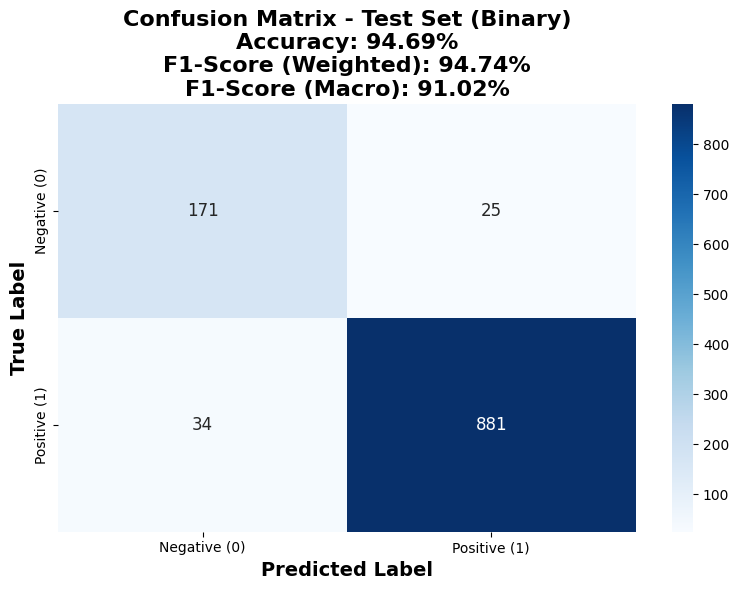

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done!


In [19]:
# ************ Final Evaluation on Test Set ******************

if best_trainer is not None:

    try:
        test_predictions = best_trainer.predict(test_dataset)

        test_preds = test_predictions.predictions.argmax(-1)

        test_accuracy = accuracy_score(y_test, test_preds)
        test_f1_weighted = f1_score(y_test, test_preds, average='weighted')
        test_f1_macro = f1_score(y_test, test_preds, average='macro')
        test_f1_binary = f1_score(y_test, test_preds, average='binary', pos_label=1)

        print(f"\n Final Results on Test Set:")
        print(f"• Accuracy: {test_accuracy*100:.2f}%")
        print(f"• F1-Score (Weighted): {test_f1_weighted*100:.2f}%")
        print(f"• F1-Score (Macro): {test_f1_macro*100:.2f}%")
        print(f"• F1-Score (Binary): {test_f1_binary*100:.2f}%")

        print("\n Report:")
        print(classification_report(y_test, test_preds,
                                   target_names=['Class 0 (Neg)', 'Class 1 (Pos)'],
                                   digits=3))

        cm = confusion_matrix(y_test, test_preds)

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Negative (0)', 'Positive (1)'],
                    yticklabels=['Negative (0)', 'Positive (1)'],
                    annot_kws={'size': 12})
        plt.xlabel('Predicted Label', fontsize=14, fontweight='bold')
        plt.ylabel('True Label', fontsize=14, fontweight='bold')
        plt.title(f'Confusion Matrix - Test Set (Binary)\nAccuracy: {test_accuracy*100:.2f}%\nF1-Score (Weighted): {test_f1_weighted*100:.2f}%\nF1-Score (Macro): {test_f1_macro*100:.2f}%',
                  fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.savefig('confusion_matrix_5class.png', dpi=300, bbox_inches='tight')
        plt.show()

        #print("\n Confusion Matrix (Text Format):")
        #print("="*50)
        #for i, label in enumerate(class_labels):
            #for j, pred_label in enumerate(class_labels):
                #print(f"  {label} (True) → {pred_label} (Pred): {cm[i, j]}")
            #print("-"*50)


        best_model_info = {
            'model_name': MODEL_NAME,
            'combination_id': best_combination_id,
            'hyperparameters': best_hyperparams,
            'validation_accuracy': float(best_val_accuracy),
            'test_accuracy': float(test_accuracy),
            'test_f1_weighted': float(test_f1_weighted),
            'test_f1_binary': float(test_f1_binary),
            'final_model_path': final_model_dir if 'final_model_dir' in locals() else None
        }

        output_df = pd.DataFrame({
            'true_label': y_test,
            'predicted_label': test_preds
        })
        output_df.to_csv('model_predictions.csv', index=False, encoding='utf-8-sig')
        files.download('model_predictions.csv')
        print("Done!")

    except Exception as e:
        print(f"ERROR!!!: {str(e)}")
        import traceback
        traceback.print_exc()
        test_accuracy = 0
        test_f1_weighted = 0
        test_f1_binary = 0

else:
    print("ERROR!!!")
    test_accuracy = 0
    test_f1_weighted = 0
    test_f1_binary = 0